# Image segmentation on urban street scenes

This notebook currently contains:
- **Dataset exploration**: basic checks to understand the dataset structure and visualization of images with their binary masks.
- **Part 1.1: per-pixel classification**: a simple classifier (logistic regression) that predicts, from the RGB values of a single pixel, whether it belongs to the sky or not (binary segmentation: sky vs. everything else).

In [5]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (7, 7)

import skimage
import skimage.io

import os

import sklearn.linear_model

In [6]:
IMG_DIR = "dataset/Cityscape Dataset/leftImg8bit"
MASK_DIR = "dataset/Fine Annotations/gtFine"

CLASS_NAMES = [
    "unlabeled", "ego vehicle", "rectification border", "out of roi", "static",
    "dynamic", "ground", "road", "sidewalk", "parking", "rail track",
    "building", "wall", "fence", "guard rail", "bridge", "tunnel", "pole",
    "polegroup", "traffic light", "traffic sign", "vegetation", "terrain",
    "sky", "person", "rider", "car", "truck", "bus", "caravan", "trailer",
    "train", "motorcycle", "bicycle",
]

SKY_ID = 23

## 0. Dataset exploration

In this section we explore the dataset to understand how it is organized and what the masks contain.

In [7]:
name = "zurich_000016_000019"
im = skimage.io.imread(f"{IMG_DIR}/train/zurich/{name}_leftImg8bit.png")
ids = skimage.io.imread(f"{MASK_DIR}/train/zurich/{name}_gtFine_labelIds.png")

print(im.shape, im.dtype)
print(ids.shape, ids.dtype, np.unique(ids))

(1024, 2048, 3) uint8
(1024, 2048) uint8 [ 1  3  4  5  7  8 11 12 17 20 21 23 24 25 26 33]


In [8]:
# Every class present in the image
for i in np.unique(ids):
    print(i, CLASS_NAMES[i])

1 ego vehicle
3 out of roi
4 static
5 dynamic
7 road
8 sidewalk
11 building
12 wall
17 pole
20 traffic sign
21 vegetation
23 sky
24 person
25 rider
26 car
33 bicycle


### Images and binary masks

We visualize the first 10 training images of Zurich next to their binary sky masks.

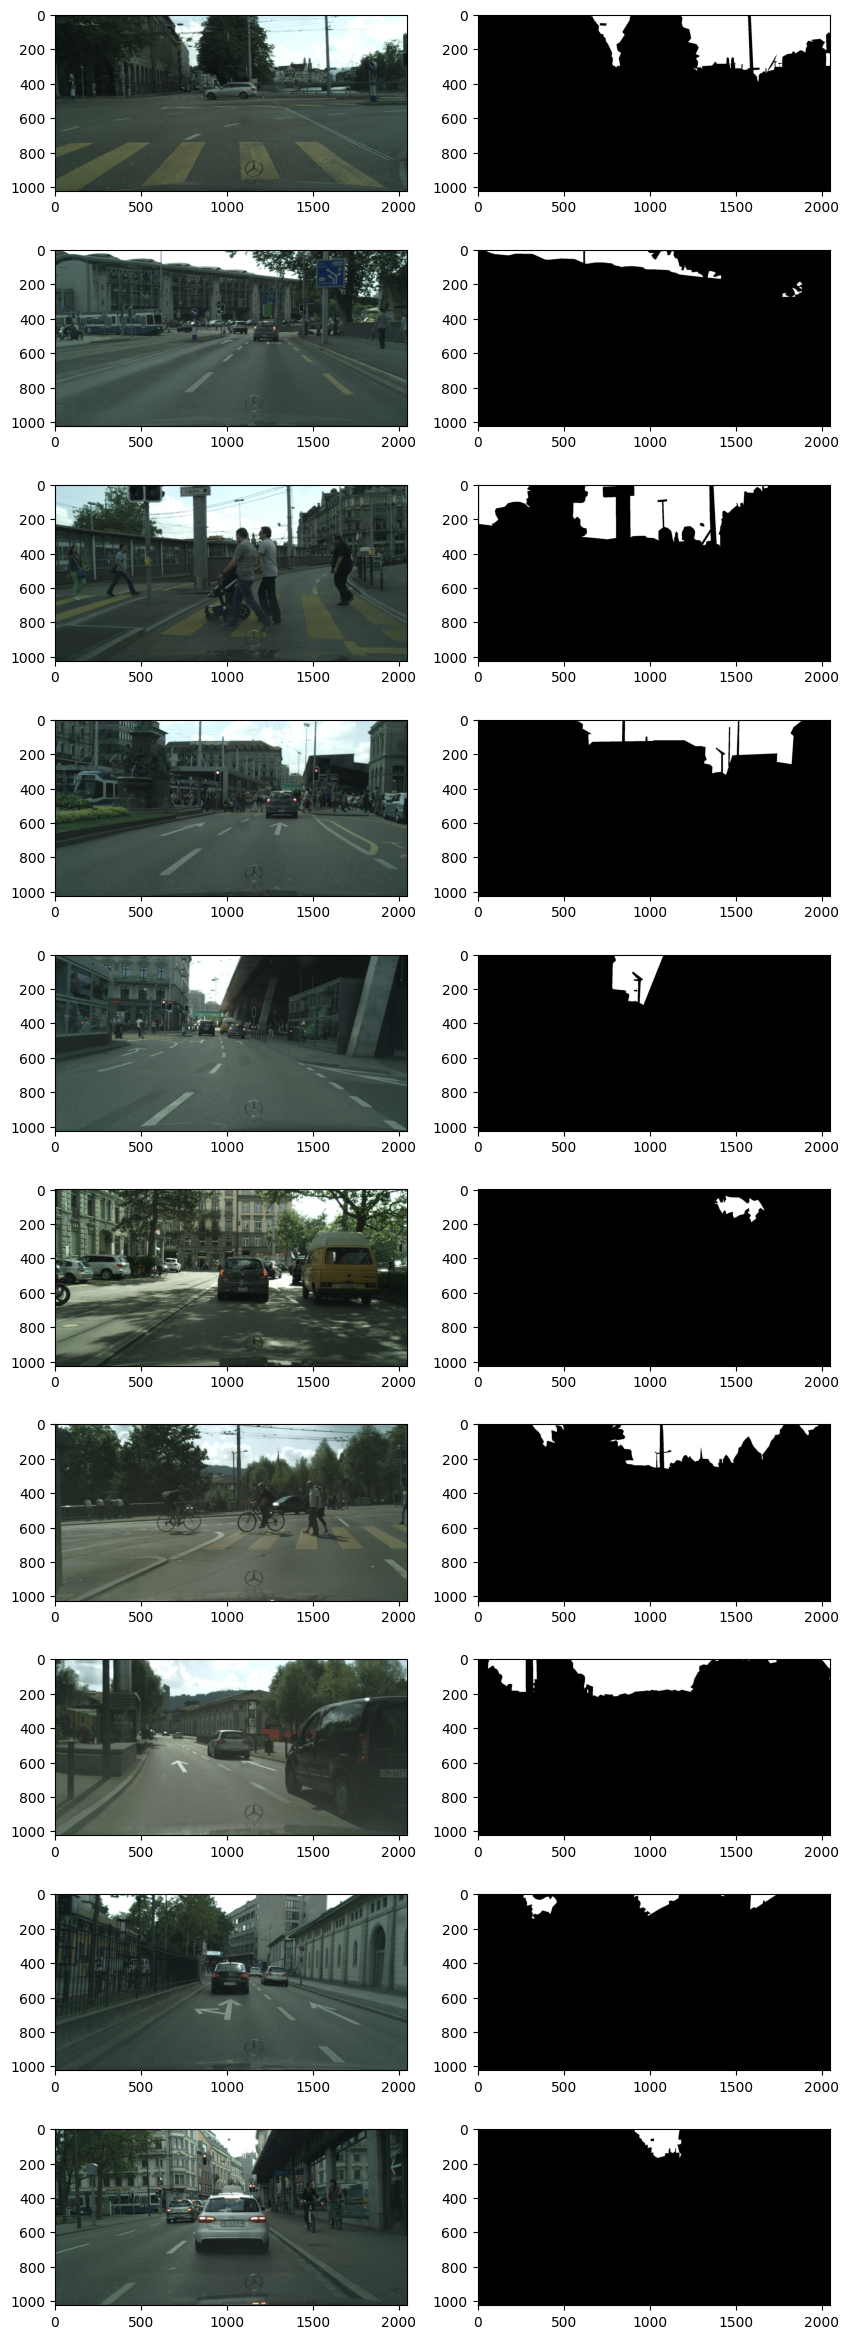

In [9]:
fig, axs = plt.subplots(nrows=10, ncols=2, figsize=(10, 30))

for i in range(10):
    name = f"zurich_{i:06d}_000019"
    im_i = skimage.io.imread(f"{IMG_DIR}/train/zurich/{name}_leftImg8bit.png")
    ids_i = skimage.io.imread(f"{MASK_DIR}/train/zurich/{name}_gtFine_labelIds.png")
    sky_mask = ids_i == SKY_ID

    axs[i, 0].imshow(im_i)
    axs[i, 1].imshow(sky_mask, cmap="gray", vmin=0, vmax=1)

plt.show()

## 1. Segmentation by classification

The goal is to build a classifier that takes as input the features computed for a given pixel of a given image, and produces as output the class of that pixel.

### 1.1 Per-pixel classifier on RGB values

The simplest classifier: the features are the 3 RGB values of one pixel, the output is the probability that the pixel is sky. We use a logistic regression.

In [10]:
# List all train set directories (18 cities)
print(os.listdir(f"{IMG_DIR}/train"))

# List first 5 images of a subdir
print(os.listdir(f"{IMG_DIR}/train/zurich")[:5])

['zurich', 'strasbourg', 'weimar', 'aachen', 'tubingen', 'jena', 'bochum', 'darmstadt', 'dusseldorf', 'hamburg', 'cologne', 'monchengladbach', 'krefeld', 'ulm', 'hanover', 'stuttgart', 'erfurt', 'bremen']
['zurich_000069_000019_leftImg8bit.png', 'zurich_000063_000019_leftImg8bit.png', 'zurich_000110_000019_leftImg8bit.png', 'zurich_000016_000019_leftImg8bit.png', 'zurich_000027_000019_leftImg8bit.png']


In [11]:
def list_images(split, k):
    """List the images of a dataset split.

    For each city in the given split (train or test) takes the first k images.
    Returns a list of (city, name) tuples, where name is the file name without
    the "_leftImg8bit.png" suffix.
    """
    
    images = []
    for city in os.listdir(f"{IMG_DIR}/{split}"):
        if city.startswith("."):
            continue
        files = sorted(os.listdir(f"{IMG_DIR}/{split}/{city}"))
        for f in files[:k]:
            name = f.replace("_leftImg8bit.png", "")
            images.append((city, name))
    return images

In [12]:
def sample_pixels(split, city, name, n):
    """Extract n random pixels from one image, with their sky label.

    Reads the image and its labelIds mask, picks n random (row, column)
    coordinates and returns:
    - X: array (n, 3) with the RGB values of the pixels
    - y: array (n,) of booleans, True where the pixel is sky
    """
    im = skimage.io.imread(f"{IMG_DIR}/{split}/{city}/{name}_leftImg8bit.png")
    ids = skimage.io.imread(f"{MASK_DIR}/{split}/{city}/{name}_gtFine_labelIds.png")
    rows = np.random.choice(ids.shape[0], n)
    cols = np.random.choice(ids.shape[1], n)
    X = im[rows, cols, :]
    y = ids[rows, cols] == SKY_ID
    return X, y

#### Building the training set
The classifier needs a table where each row is a sample. A sample is a **pixel**: the features are its 3 RGB values and the label says whether it is sky (True) or not (False), read from the binary mask at the same coordinates.

We take 10 images for each of the 18 training cities (180 images) and 50 pixels per image, for a total of 9000 samples.

In [13]:
# TRAIN SET (18 cities)
TRAIN_SPLIT = "train"
N_TRAIN_IMAGES = 10
N_TRAIN_PIXELS = 50

# 10 images for each city: 10 * 18 = 180 images
train_images = list_images(TRAIN_SPLIT, N_TRAIN_IMAGES)

# 50 pixel for each image: 50 * 180 = 9000 samples
X_list = []
y_list = []
for item in train_images:
    X, y = sample_pixels(TRAIN_SPLIT, item[0], item[1], N_TRAIN_PIXELS)
    X_list.append(X)
    y_list.append(y)

X_train = np.vstack(X_list) / 255
y_train = np.hstack(y_list)

print(X_train.shape, y_train.shape)

(9000, 3) (9000,)


#### Test set
We use the `val` split, which has real annotations, as our test set. Its 3 cities are different from the training cities, so the model is evaluated on scenes it has never seen. The test samples are built in the same way as the training ones (10 images per city, 50 pixels per image).

In [14]:
# TEST SET (3 cities)
TEST_SPLIT = "val"
N_TEST_IMAGES = 10
N_TEST_PIXELS = 50

# 10 images for each city: 10 * 3 = 30 images
test_images = list_images(TEST_SPLIT, N_TEST_IMAGES)

# 50 pixel for each image: 50 * 30 = 1500 samples
X_list = []
y_list = []
for item in test_images:
    X, y = sample_pixels(TEST_SPLIT, item[0], item[1], N_TEST_PIXELS)
    X_list.append(X)
    y_list.append(y)

X_test = np.vstack(X_list) / 255
y_test = np.hstack(y_list)

print(X_test.shape, y_test.shape)

(1500, 3) (1500,)


#### Training and evaluation
We train a logistic regression on the training samples and compute its accuracy on both sets. Since sky is a small fraction of the pixels, accuracy alone is misleading: we compare it with the baseline of a model that always predicts "not sky".

In [15]:
# MODEL
clf = sklearn.linear_model.LogisticRegression()
clf.fit(X_train, y_train)

y_pred_train = clf.predict(X_train)
y_pred_test = clf.predict(X_test)

print("Train accuracy:", np.mean(y_pred_train == y_train))
print("Test accuracy:", np.mean(y_pred_test == y_test))
print("Baseline (always not sky):", 1 - np.mean(y_test))

Train accuracy: 0.9727777777777777
Test accuracy: 0.9493333333333334
Baseline (always not sky): 0.9473333333333334


#### Evaluation: AUC, accuracy and confusion matrix

Besides accuracy, we compute the AUC and the confusion matrix. Since about 94% of test pixels are not sky, the "always not sky" baseline already scores 0.938 accuracy, so the confusion matrix is what shows how well we detect sky pixels, which is what matters.

In [16]:
import sklearn.metrics
def evaluate(clf, X, y, title):
    proba = clf.predict_proba(X)[:, 1]
    pred = proba > 0.5 # is > 0.5 -> sky
    acc = sklearn.metrics.accuracy_score(y, pred) # % of correctly classified pixels
    auc = sklearn.metrics.roc_auc_score(y, proba) # class separation, threshold-independent (0.5 = random, 1 = perfect)
    cm = sklearn.metrics.confusion_matrix(y, pred) # 2x2 table of hits and errors
    print(f"{title}: accuracy = {acc:.3f}, AUC = {auc:.3f}")
    print(cm)
    return proba, cm

proba_train, cm_train = evaluate(clf, X_train, y_train, "Train")
proba_test, cm_test = evaluate(clf, X_test, y_test, "Test")

tn, fp, fn, tp = cm_test.ravel()
print("Recall sky :", tp / (tp + fn)) # How many pixel are sky
print("Precision sky:", tp / (tp + fp)) # How many are true skt

Train: accuracy = 0.973, AUC = 0.988
[[8470  113]
 [ 132  285]]
Test: accuracy = 0.949, AUC = 0.977
[[1391   30]
 [  46   33]]
Recall sky : 0.4177215189873418
Precision sky: 0.5238095238095238


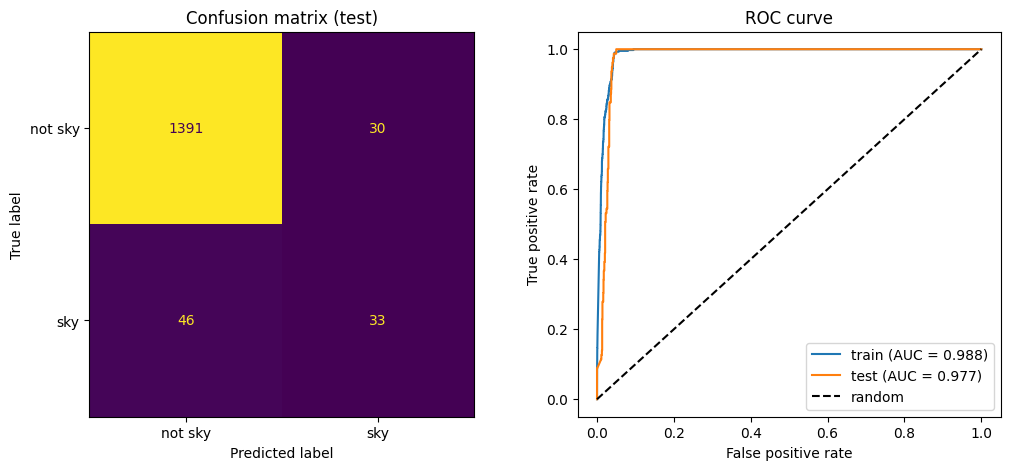

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix (rows = true class, columns = predicted class)
sklearn.metrics.ConfusionMatrixDisplay(cm_test, display_labels=["not sky", "sky"]).plot(ax=axs[0], colorbar=False, values_format="d")
axs[0].set_title("Confusion matrix (test)")

# ROC curve
for proba, y, label in [(proba_train, y_train, "train"), (proba_test, y_test, "test")]:
    fpr, tpr, _ = sklearn.metrics.roc_curve(y, proba)
    auc = sklearn.metrics.roc_auc_score(y, proba)
    axs[1].plot(fpr, tpr, label=f"{label} (AUC = {auc:.3f})")
axs[1].plot([0, 1], [0, 1], "k--", label="random")
axs[1].set_xlabel("False positive rate")
axs[1].set_ylabel("True positive rate")
axs[1].set_title("ROC curve")
axs[1].legend()

plt.show()

**Results.** The classifier separates sky from non-sky very well: the ROC curves hug the top-left corner, with AUC = 0.987 (train) and 0.980 (test).

#### Segmenting whole test images

Once trained, the classifier is applied to **every pixel** of an image: we flatten the image from (H, W, 3) to (H*W, 3), predict the sky probability of each pixel, and reshape the result back to (H, W). Thresholding the probability at 0.5 gives the predicted binary mask.

In [18]:
def segment_image(clf, im):
    """Apply a per-pixel classifier to a whole RGB image.

    Returns the (H, W) map of the probability that each pixel is sky.
    """
    h = im.shape[0]
    w = im.shape[1]
    X = im.reshape(h * w, 3) / 255
    proba = clf.predict_proba(X)[:, 1]
    return proba.reshape(h, w)

In [ ]:
# Pick 6 test images evenly spaced across the test set
n_show = 6
step = len(test_images) // n_show

fig, axs = plt.subplots(n_show, 4, figsize=(20, 2.6 * n_show))

titles = ["Image", "Ground truth (sky)", "Predicted probability", "Predicted mask (p > 0.5)"]
for col in range(4):
    axs[0, col].set_title(titles[col])

for i in range(n_show):
    city, name = test_images[i * step]
    im = skimage.io.imread(f"{IMG_DIR}/{TEST_SPLIT}/{city}/{name}_leftImg8bit.png")
    ids = skimage.io.imread(f"{MASK_DIR}/{TEST_SPLIT}/{city}/{name}_gtFine_labelIds.png")

    gt = ids == SKY_ID               # true sky mask (True = sky)
    proba = segment_image(clf, im)   # per-pixel probability of sky
    pred = proba > 0.5               # predicted sky mask

    axs[i, 0].imshow(im)
    axs[i, 1].imshow(gt, cmap="gray")
    axs[i, 2].imshow(proba, cmap="gray", vmin=0, vmax=1)
    axs[i, 3].imshow(pred, cmap="gray")

    for col in range(4):
        axs[i, col].set_xticks([])
        axs[i, col].set_yticks([])
    axs[i, 0].set_ylabel(city)

    # Per-image metrics: accuracy and IoU
    acc = np.mean(pred == gt)
    iou = (pred & gt).sum() / (pred | gt).sum()      # intersection over union of sky
    print(f"{city}/{name}: accuracy = {acc:.3f}, IoU sky = {iou:.3f}")

plt.tight_layout()
plt.show()

munster/munster_000000_000019: accuracy = 0.979, IoU sky = 0.720
munster/munster_000005_000019: accuracy = 0.997, IoU sky = 0.657
lindau/lindau_000000_000019: accuracy = 0.882, IoU sky = 0.067
lindau/lindau_000005_000019: accuracy = 0.873, IoU sky = 0.036
frankfurt/frankfurt_000000_000294: accuracy = 0.954, IoU sky = 0.279
frankfurt/frankfurt_000000_002196: accuracy = 0.985, IoU sky = 0.757
